# Assignment 1: Sales decomposition

**Goal:** split daily total sales of store `CA_1` into trend, weekly seasonality and residual (STL, period = 7, additive).

In [1]:
from pathlib import Path
import importlib.util

import matplotlib.pyplot as plt
import pandas as pd

if importlib.util.find_spec("statsmodels") is None:
    raise ImportError("This notebook requires statsmodels. Install it in the notebook's Python environment.")
from statsmodels.tsa.seasonal import STL

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 12)

search_roots = [Path.cwd(), *Path.cwd().parents]
DATA_DIR = next(
    (root / "m5-forecasting-accuracy" for root in search_roots
     if (root / "m5-forecasting-accuracy").is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find m5-forecasting-accuracy. Run from the workspace or its notebooks folder."
    )

SALES_PATH = DATA_DIR / "sales_train_validation.csv"
CALENDAR_PATH = DATA_DIR / "calendar.csv"
STORE_ID = "CA_1"
SEASONAL_PERIOD = 7
print(f"Data folder: {DATA_DIR}")

Data folder: c:\Users\mandabhushan\OneDrive - Nagarro\Documents\D\Learnings\Projects\Time_series\m5-forecasting-accuracy


## Prepare daily store sales

In [2]:
header = pd.read_csv(SALES_PATH, nrows=0).columns.tolist()
day_cols = [column for column in header if column.startswith("d_")]
if not day_cols:
    raise ValueError("No daily sales columns beginning with 'd_' were found.")

store_totals = None
for chunk in pd.read_csv(
    SALES_PATH,
    usecols=["store_id"] + day_cols,
    chunksize=512,
):
    store_rows = chunk.loc[chunk["store_id"] == STORE_ID, day_cols]
    if not store_rows.empty:
        chunk_totals = store_rows.sum(axis=0)
        store_totals = chunk_totals if store_totals is None else store_totals.add(chunk_totals)

if store_totals is None:
    raise ValueError(f"Store {STORE_ID!r} was not found in the sales file.")

calendar = pd.read_csv(CALENDAR_PATH, usecols=["d", "date", "weekday"])
calendar["date"] = pd.to_datetime(calendar["date"])
sales = pd.DataFrame({"d": day_cols, "sales": store_totals.reindex(day_cols).to_numpy()})
sales = sales.merge(calendar, on="d", how="left", validate="one_to_one")
sales = sales.sort_values("date").set_index("date", drop=False)

if sales["date"].isna().any() or sales["sales"].isna().any():
    raise ValueError("Sales contain missing dates or values after joining to the calendar.")
if not sales.index.is_unique or not sales.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all():
    raise ValueError("Expected one consecutive daily observation per date.")

y = sales["sales"].astype(float).rename("sales")
print(f"Store: {STORE_ID}")
print(f"Period: {y.index.min().date()} to {y.index.max().date()} ({len(y):,} days)")
print(f"Daily sales range: {y.min():,.0f} to {y.max():,.0f}; mean: {y.mean():,.1f}")
display(sales[["d", "weekday", "sales"]].head())

Store: CA_1
Period: 2011-01-29 to 2016-04-24 (1,913 days)
Daily sales range: 0 to 6,948; mean: 4,024.2


,d,weekday,sales
date,,,
2011-01-29,d_1,Saturday,4337
2011-01-30,d_2,Sunday,4155
2011-01-31,d_3,Monday,2816
2011-02-01,d_4,Tuesday,3051
2011-02-02,d_5,Wednesday,2630


## Original series

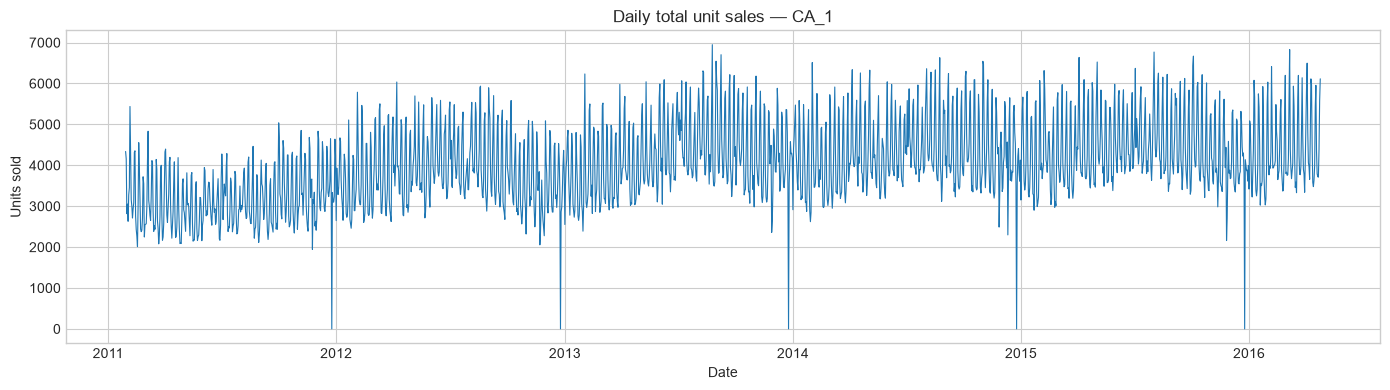

In [3]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index, y, linewidth=0.8)
ax.set(title=f"Daily total unit sales — {STORE_ID}", xlabel="Date", ylabel="Units sold")
plt.tight_layout()
plt.show()

## STL decomposition

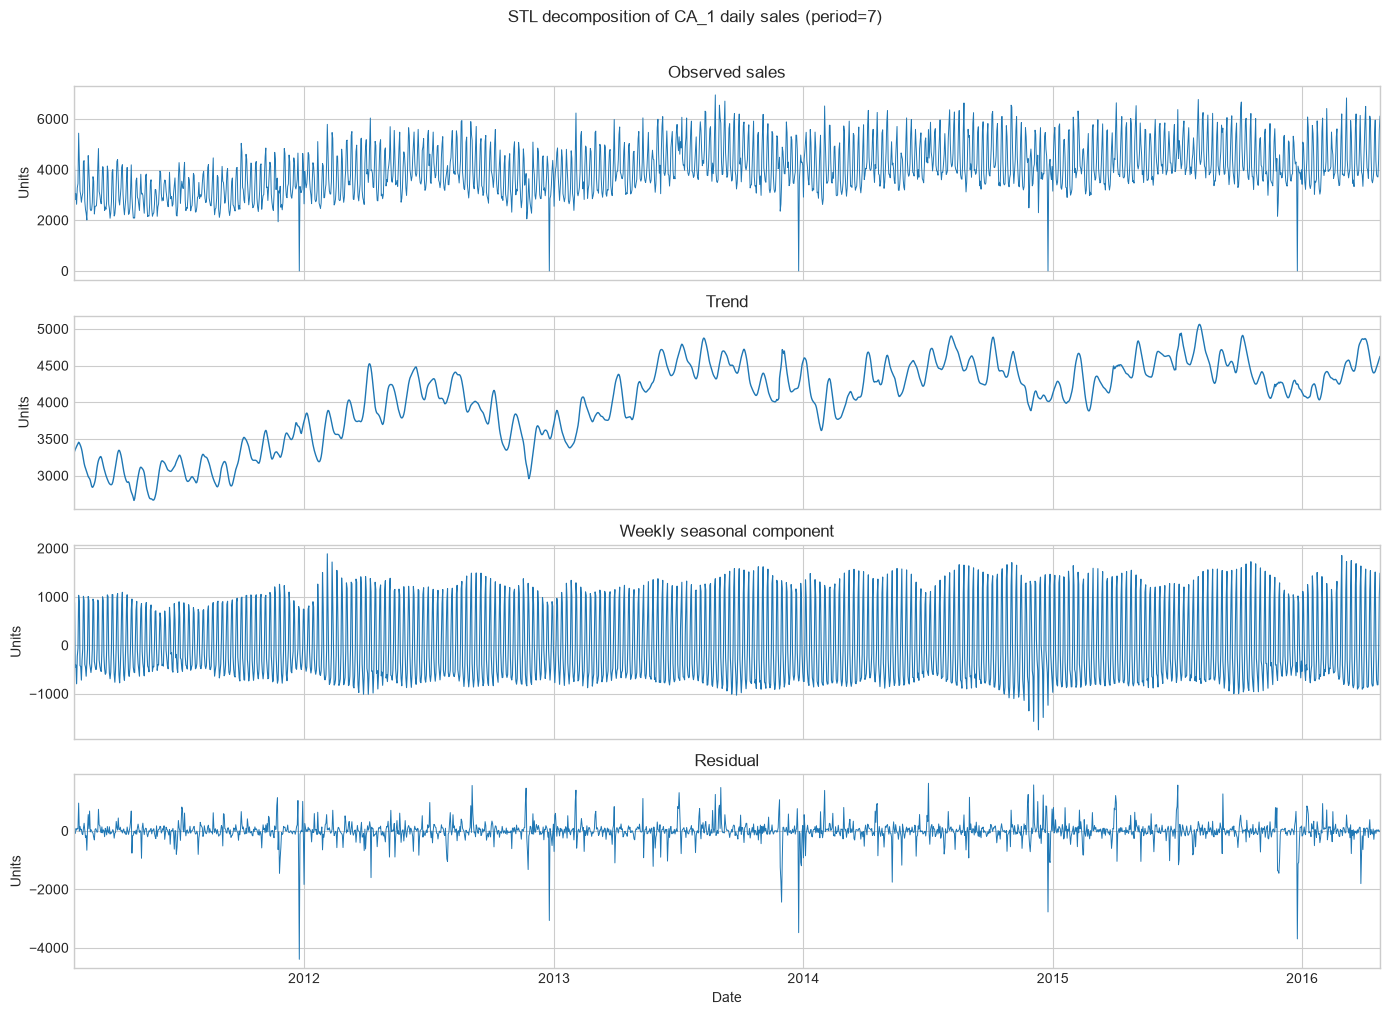

,count,mean,std,min,25%,50%,75%,max
observed,1913.0,4024.158913,991.847206,0.000000,3349.000000,3902.000000,4633.000000,6948.000000
trend,1913.0,4031.386918,537.694703,2662.392816,3700.762954,4154.253109,4439.101919,5061.840070
seasonal,1913.0,1.047447,782.611964,-1745.647656,-648.888720,-237.359122,850.602656,1887.232247
residual,1913.0,-8.275452,370.111055,-4395.971072,-92.515684,0.835535,92.541403,1629.779107


In [4]:
stl = STL(y, period=SEASONAL_PERIOD, robust=True)
result = stl.fit()
components = pd.DataFrame({
    "observed": y,
    "trend": result.trend,
    "seasonal": result.seasonal,
    "residual": result.resid,
})

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
components["observed"].plot(ax=axes[0], linewidth=0.7, title="Observed sales")
components["trend"].plot(ax=axes[1], linewidth=1.0, title="Trend")
components["seasonal"].plot(ax=axes[2], linewidth=0.8, title="Weekly seasonal component")
components["residual"].plot(ax=axes[3], linewidth=0.7, title="Residual")
axes[0].set_ylabel("Units")
axes[1].set_ylabel("Units")
axes[2].set_ylabel("Units")
axes[3].set_ylabel("Units")
axes[3].set_xlabel("Date")
fig.suptitle(f"STL decomposition of {STORE_ID} daily sales (period={SEASONAL_PERIOD})", y=1.01)
plt.tight_layout()
plt.show()

display(components.describe().T)

## Weekday effect

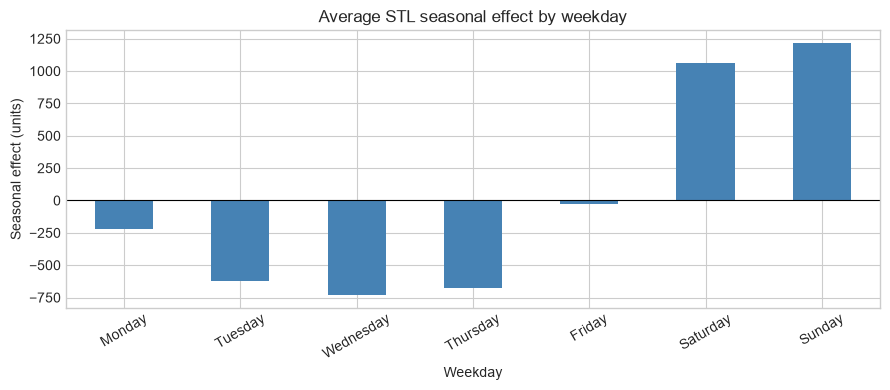

,average seasonal effect (units)
weekday,
Monday,-221.422508
Tuesday,-623.767896
Wednesday,-731.720393
Thursday,-678.578705
Friday,-23.615195
Saturday,1061.982927
Sunday,1216.116885


In [5]:
seasonal_by_weekday = (
    components[["seasonal"]]
    .join(sales["weekday"])
    .groupby("weekday")["seasonal"]
    .mean()
)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
seasonal_by_weekday = seasonal_by_weekday.reindex(weekday_order).dropna()

fig, ax = plt.subplots(figsize=(9, 4))
seasonal_by_weekday.plot(kind="bar", ax=ax, color="steelblue")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Average STL seasonal effect by weekday", xlabel="Weekday", ylabel="Seasonal effect (units)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(seasonal_by_weekday.to_frame("average seasonal effect (units)"))

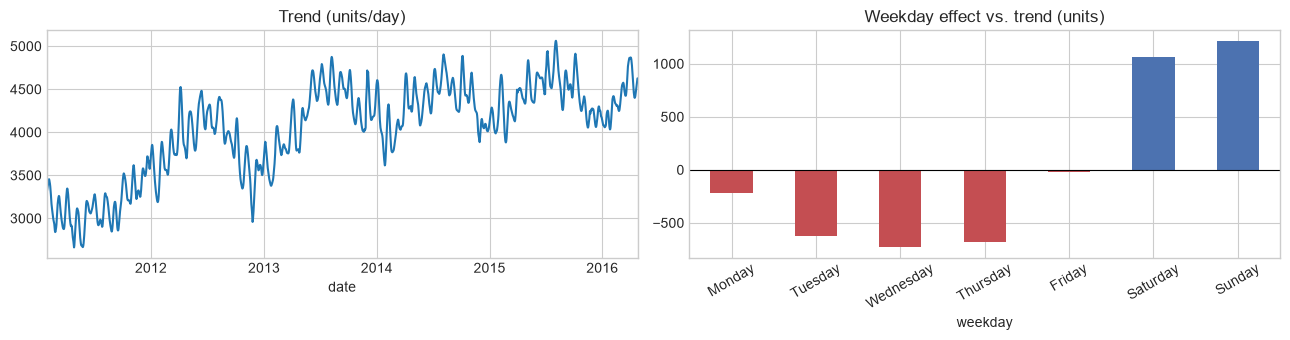

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
components["trend"].plot(ax=axes[0], title="Trend (units/day)")
seasonal_by_weekday.plot(kind="bar", ax=axes[1], color=["#4c72b0" if v >= 0 else "#c44e52" for v in seasonal_by_weekday],
                         title="Weekday effect vs. trend (units)", rot=30)
axes[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


## Conclusion

- **Trend:** rising, about 3,300 to 4,600 units/day (+40%), peak near 5,060 in Aug 2015, flat afterwards.
- **Weekly pattern:** Sat/Sun are about +1,100 to +1,200 units above trend; Tue-Thu are about -600 to -730 below.
- **Residual:** centred on zero (sd about 370); the largest drop is Christmas Day.
- **Limit:** one store, weekly seasonality only.